In [4]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
 
print("Libararies Exported")




Libararies Exported


Visualisations are stored in output folder acrouding to my project structure, if running all the codes caused any error , kindly comment the below lines or refer the outputs folder in the repo.
--plt.savefig("../outputs/chart5_box_plot.png",bbox_inches="tight")

Task 1 - Load Dataset 

In [5]:
df=pd.read_csv("../Data/aqi_weather_enso_merged_reduced.csv")
print("Loaded csv file successfully")

Loaded csv file successfully


In [6]:
print("First five rows:")
df.head(5)

First five rows:


,City,Date,season,AQI_Bucket,avg_temp,min_temp,max_temp,wind_speed,air_pressure,rainfall,AQI,YYYY,MM,ONI
0,Ahmedabad,2018-01-01,Winter,Poor,20.3,10.8,27.2,5.4,1011.8,NaN,278.0,2018,1,-0.77
1,Ahmedabad,2018-01-02,Winter,Poor,19.8,12.2,26.0,8.5,1012.5,NaN,256.0,2018,1,-0.77
2,Ahmedabad,2018-01-03,Winter,Poor,19.5,12.5,26.0,8.3,1013.3,NaN,300.0,2018,1,-0.77
3,Ahmedabad,2018-01-04,Winter,Severe,19.6,10.5,28.0,4.1,1013.7,NaN,532.0,2018,1,-0.77
4,Ahmedabad,2018-01-05,Winter,Severe,19.5,8.6,27.0,3.0,1012.8,NaN,534.0,2018,1,-0.77


In [7]:
print("Datatypes:")
df.dtypes

Datatypes:


City             object
Date             object
season           object
AQI_Bucket       object
avg_temp        float64
min_temp        float64
max_temp        float64
wind_speed      float64
air_pressure    float64
rainfall        float64
AQI             float64
YYYY              int64
MM                int64
ONI             float64
dtype: object

In [8]:
print("DataFrame Shape:")
df.shape

DataFrame Shape:


(13709, 14)

Task 2 - Null Value Analysis and Handling

In [9]:
print("Null Value count")
df.isnull().sum()

Null Value count


City               0
Date               0
season             0
AQI_Bucket       557
avg_temp           0
min_temp         393
max_temp         835
wind_speed      1574
air_pressure    3908
rainfall        9128
AQI              557
YYYY               0
MM                 0
ONI                0
dtype: int64

In [10]:
print("Percentage of missing values")
round((df.isnull().sum() / df.shape[0] )* 100,2)

Percentage of missing values


City             0.00
Date             0.00
season           0.00
AQI_Bucket       4.06
avg_temp         0.00
min_temp         2.87
max_temp         6.09
wind_speed      11.48
air_pressure    28.51
rainfall        66.58
AQI              4.06
YYYY             0.00
MM               0.00
ONI              0.00
dtype: float64

In [11]:
# Copying original datset to other Datframe to perfome cleaning activities 





df_clean=df.copy()


print("Datframe copied")
print(f"First 5 rows:\n{df.head(5)}")
print(f"Datatypes:\n{df.dtypes}")
print(f"Shape of Dataframe:\n{df.shape}")
print(f"Null value counts:\n{df.isnull().sum()}")
print(f"Null value percentage:\n{round((df.isnull().sum() / df.shape[0] )* 100,2)}")


print("Datframe copied")
print(f"First 5 rows:\n{df_clean.head(5)}")
print(f"Datatypes:\n{df_clean.dtypes}")
print(f"Shape of Dataframe:\n{df_clean.shape}")
print(f"Null value counts:\n{df_clean.isnull().sum()}")
print(f"Null value percentage:\n{round((df_clean.isnull().sum() / df_clean.shape[0] )* 100,2)}")


Datframe copied
First 5 rows:
        City        Date  season AQI_Bucket  avg_temp  min_temp  max_temp  \
0  Ahmedabad  2018-01-01  Winter       Poor      20.3      10.8      27.2   
1  Ahmedabad  2018-01-02  Winter       Poor      19.8      12.2      26.0   
2  Ahmedabad  2018-01-03  Winter       Poor      19.5      12.5      26.0   
3  Ahmedabad  2018-01-04  Winter     Severe      19.6      10.5      28.0   
4  Ahmedabad  2018-01-05  Winter     Severe      19.5       8.6      27.0   

   wind_speed  air_pressure  rainfall    AQI  YYYY  MM   ONI  
0         5.4        1011.8       NaN  278.0  2018   1 -0.77  
1         8.5        1012.5       NaN  256.0  2018   1 -0.77  
2         8.3        1013.3       NaN  300.0  2018   1 -0.77  
3         4.1        1013.7       NaN  532.0  2018   1 -0.77  
4         3.0        1012.8       NaN  534.0  2018   1 -0.77  
Datatypes:
City             object
Date             object
season           object
AQI_Bucket       object
avg_temp        float6

In [12]:
#creating median for max and min temp as well as air_pressure
print("Handling numeric fields with median")
air_pressure_median=df_clean["air_pressure"].median()
max_temp_median=df_clean["max_temp"].median()
min_temp_median=df_clean["min_temp"].median()
wind_speed_median =df_clean["wind_speed"].median()


df_clean["air_pressure"]=df_clean["air_pressure"].fillna(air_pressure_median)
df_clean["max_temp"]=df_clean["max_temp"].fillna(max_temp_median)
df_clean["min_temp"]=df_clean["min_temp"].fillna(min_temp_median)
df_clean["wind_speed"]=df_clean["wind_speed"].fillna(wind_speed_median)

print("Dropping rainfall column and 2 other fields like year and month which is already present in Date field:")
df_clean=df_clean.drop(columns=["rainfall"])
df_clean=df_clean.drop(columns=["YYYY"])
df_clean=df_clean.drop(columns=["MM"])

print("Dropping AQI and AQI Bucket null rows as this dataset used for Supervised training:")
df_clean=df_clean.dropna(subset=["AQI"])
df_clean=df_clean.dropna(subset=["AQI_Bucket"])
print("Filled numeric columns with median, dropped required field and rows  and provied justifctaion in README file ")


Handling numeric fields with median
Dropping rainfall column and 2 other fields like year and month which is already present in Date field:
Dropping AQI and AQI Bucket null rows as this dataset used for Supervised training:
Filled numeric columns with median, dropped required field and rows  and provied justifctaion in README file 


In [13]:
#checkingggg
print(f"First 5 rows:\n{df_clean.head(5)}")
print(f"Datatypes:\n{df_clean.dtypes}")
print(f"Shape of Dataframe:\n{df_clean.shape}")
print(f"Null value counts:\n{df_clean.isnull().sum()}")
print(f"Null value percentage:\n{round((df_clean.isnull().sum() / df_clean.shape[0] )* 100,2)}")

First 5 rows:
        City        Date  season AQI_Bucket  avg_temp  min_temp  max_temp  \
0  Ahmedabad  2018-01-01  Winter       Poor      20.3      10.8      27.2   
1  Ahmedabad  2018-01-02  Winter       Poor      19.8      12.2      26.0   
2  Ahmedabad  2018-01-03  Winter       Poor      19.5      12.5      26.0   
3  Ahmedabad  2018-01-04  Winter     Severe      19.6      10.5      28.0   
4  Ahmedabad  2018-01-05  Winter     Severe      19.5       8.6      27.0   

   wind_speed  air_pressure    AQI   ONI  
0         5.4        1011.8  278.0 -0.77  
1         8.5        1012.5  256.0 -0.77  
2         8.3        1013.3  300.0 -0.77  
3         4.1        1013.7  532.0 -0.77  
4         3.0        1012.8  534.0 -0.77  
Datatypes:
City             object
Date             object
season           object
AQI_Bucket       object
avg_temp        float64
min_temp        float64
max_temp        float64
wind_speed      float64
air_pressure    float64
AQI             float64
ONI           

Task 3 - Duplicate Analysis

In [14]:

duplicate_count = df_clean.duplicated().sum()
print(f"Number of duplicate rows: {duplicate_count}")
print(f"Dataset shape beofore removing duplicates: {df_clean.shape}")


df_clean = df_clean.drop_duplicates()

print(f"Dataset shape after removing duplicates: {df_clean.shape}")

Number of duplicate rows: 0
Dataset shape beofore removing duplicates: (13152, 11)
Dataset shape after removing duplicates: (13152, 11)


Task 4 - Datatype Correlation 

In [15]:
memory_before=df_clean.memory_usage(deep=True).sum()
print(memory_before)

df_clean["Date"] = pd.to_datetime(df_clean["Date"])
df_clean["season"] = df_clean["season"].astype("category")
memory_after=df_clean.memory_usage(deep=True).sum()

print(f"Memory usage before the conversion: {memory_before}")
print(f"Memory usage after the conversion: {memory_after}")
print(f"Memort usage reduced: {memory_before-memory_after}")



3871939
Memory usage before the conversion: 3871939
Memory usage after the conversion: 2477816
Memort usage reduced: 1394123


Task 5 - Descriptiv and Skewness Analysis

In [16]:
numeric_df = df_clean.select_dtypes(include=["number"])

numeric_df.describe()



,avg_temp,min_temp,max_temp,wind_speed,air_pressure,AQI,ONI
count,13152.000000,13152.000000,13152.000000,13152.000000,13152.000000,13152.000000,13152.000000
mean,26.205357,21.080185,32.250596,8.370015,1009.471234,155.243841,0.356512
std,5.665352,6.027354,5.270955,3.932325,4.859407,152.342980,0.446509
min,5.000000,0.000000,8.400000,0.000000,955.900000,14.000000,-0.770000
25%,23.362500,17.866667,29.600000,5.800000,1007.900000,74.000000,0.140000
50%,27.366667,22.729167,32.600000,8.000000,1009.900000,105.000000,0.520000
75%,29.950000,25.466667,35.050000,10.300000,1011.933333,172.000000,0.660000
max,40.200000,35.000000,87.000000,29.500000,1023.700000,2049.000000,0.970000


In [17]:
print("Skewness:") 
numeric_df.skew()


Skewness:


avg_temp       -0.817665
min_temp       -0.944734
max_temp       -0.351548
wind_speed      0.917156
air_pressure   -0.763975
AQI             4.054662
ONI            -0.848617
dtype: float64

Task 6 - Outlier Detection 

In [18]:
df_clean["min_temp"].min()

np.float64(0.0)

In [19]:
def detect_outliers_iqr(dataframe, column):
   Q1 = dataframe[column].quantile(0.25)
   Q3 = dataframe[column].quantile(0.75)
   IQR = Q3 - Q1
   
   lower_bound = Q1 - 1.5 * IQR
   upper_bound = Q3 + 1.5 * IQR

   outliers = dataframe[
       (dataframe[column] < lower_bound) |
       (dataframe[column] > upper_bound)
   ]

   print(f"Column: {column}")
   print(f"Q1: {Q1:.2f}")
   print(f"Q3: {Q3:.2f}")
   print(f"IQR: {IQR:.2f}")
   print(f"Lower bound: {lower_bound:.2f}")
   print(f"Upper bound: {upper_bound:.2f}")
#    print(f"Outliers found: {len(outliers)} ({len(outliers)/len(dataframe)*100:.1f}%)")
   print(f"Outlier Rows: {outliers.shape[0]}")
   return outliers



aqi_outliers = detect_outliers_iqr(df_clean, "AQI")
temp_outliers = detect_outliers_iqr(df_clean, "min_temp")
# print(f"AQI outliers rows: {aqi_outliers.head()}")
# print(f"AQI outliers count: {aqi_outliers.shape}")
# print(f"Temp outliers rows: {temp_outliers.head()}")
# print(f"Temp outliers count: {temp_outliers.shape}")

Column: AQI
Q1: 74.00
Q3: 172.00
IQR: 98.00
Lower bound: -73.00
Upper bound: 319.00
Outlier Rows: 1362
Column: min_temp
Q1: 17.87
Q3: 25.47
IQR: 7.60
Lower bound: 6.47
Upper bound: 36.87
Outlier Rows: 307


Task 7- Visualization
7a Line Chart




1.Line Plot


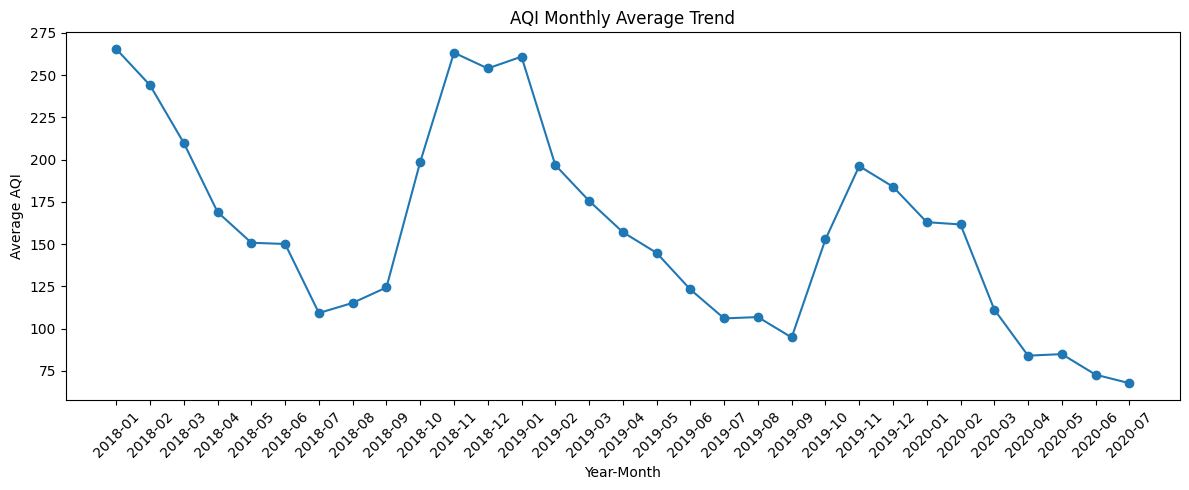

In [20]:
print("1.Line Plot")
#Date Vs AQI --> Extracting Year and Month and grouping it by AQI to get visualise for Yearly monthwise AQI since Date filed is little harder to visulaise for all the dates 
monthly_average = df_clean.groupby([df_clean["Date"].dt.year.rename("Year"),
                                     df_clean["Date"].dt.month.rename("Month")])["AQI"].mean().round(2).reset_index(name="Avg_AQI")

monthly_average["YearMonth"]=monthly_average["Year"].astype(str)+"-"+monthly_average["Month"].astype(str).str.zfill(2) #--> formmating to 2 digits as per pandas documenttaion 

# print(monthly_average)

plt.figure(figsize=(12,5))
plt.plot(monthly_average["YearMonth"],monthly_average["Avg_AQI"],marker="o")
plt.title("AQI Monthly Average Trend") 
plt.xlabel("Year-Month")
plt.ylabel("Average AQI")
plt.xticks(rotation=45) #-- found in overlapping pandas documenation 
plt.tight_layout()
plt.savefig("../outputs/chart1_Line_plot.png",bbox_inches="tight")
plt.show()


7b Bar chart

2. Bar chart


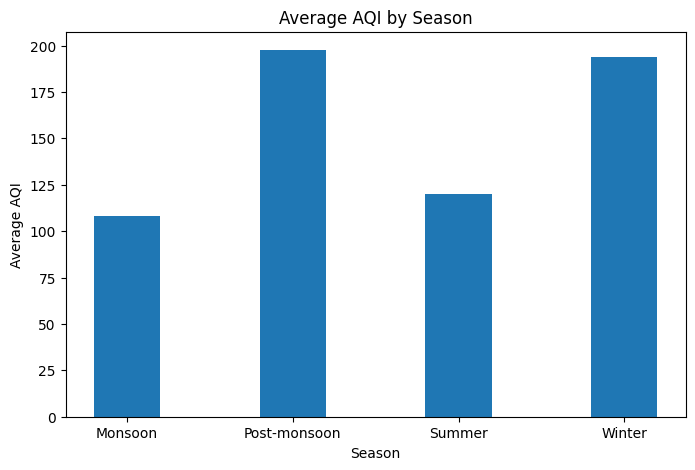

In [21]:
print("2. Bar chart")
grouped = df_clean.groupby("season",observed=True)["AQI"].mean()
plt.figure(figsize=(8,5))
plt.bar(grouped.index,grouped.values,width=0.4)
plt.xlabel("Season")
plt.ylabel("Average AQI")
plt.title("Average AQI by Season")
plt.savefig("../outputs/chart2_Bar_chart.png",bbox_inches="tight")
plt.show()

7c Histogram

3. Histogram


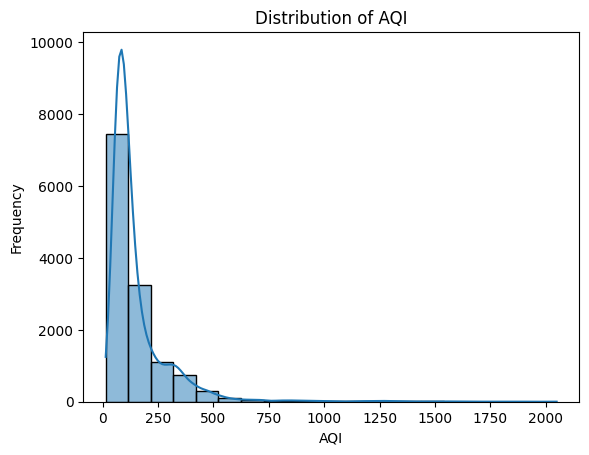

In [22]:
print("3. Histogram")
sns.histplot(data=df_clean,x="AQI",bins=20,kde=True)
plt.title("Distribution of AQI")
plt.xlabel("AQI")
plt.ylabel("Frequency")
plt.savefig("../outputs/chart3_Histogram.png",bbox_inches="tight")
plt.show()

7d Scatter Plot 

4 Scatter plot


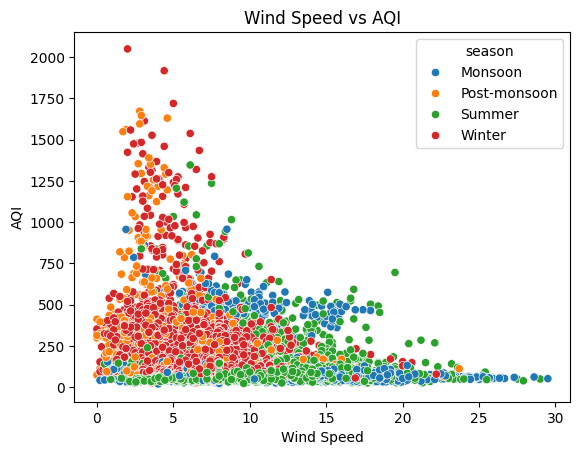

In [23]:
print("4 Scatter plot")
sns.scatterplot(x='wind_speed', y='AQI', data=df_clean,hue=df_clean["season"])
plt.title('Wind Speed vs AQI')
plt.xlabel('Wind Speed')
plt.ylabel('AQI')
plt.savefig("../outputs/chart4_Scatter_plot.png",bbox_inches="tight")
plt.show()

7 e Box plot

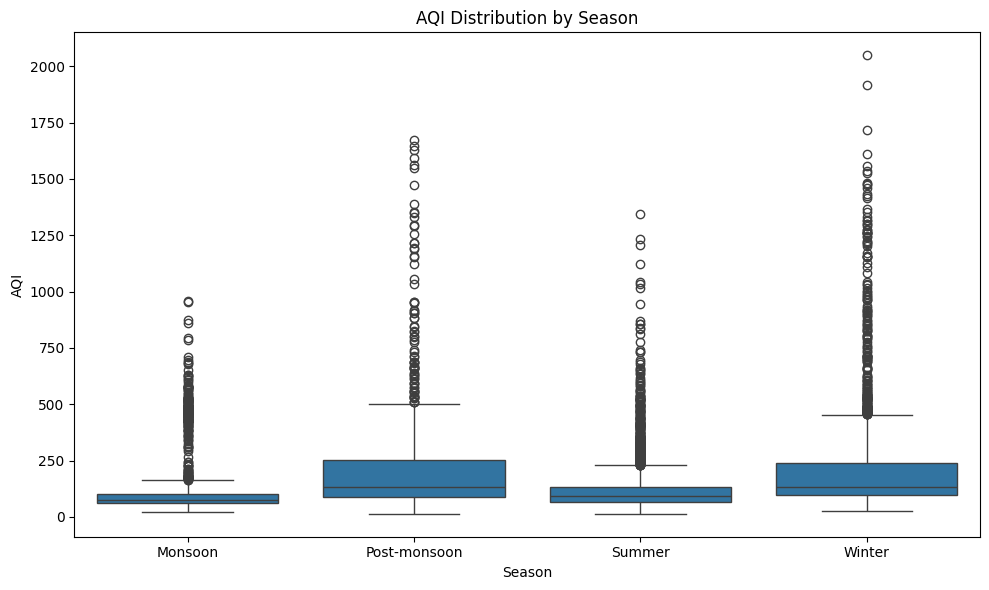

In [24]:
plt.figure(figsize=(10,6))
sns.boxplot(data=df_clean,
           x="season",
           y="AQI")
        


plt.title("AQI Distribution by Season")
plt.xlabel("Season")
plt.ylabel("AQI")

plt.tight_layout()
plt.savefig("../outputs/chart5_box_plot.png",bbox_inches="tight")
plt.show()

Task 8 - Correlation heatmap

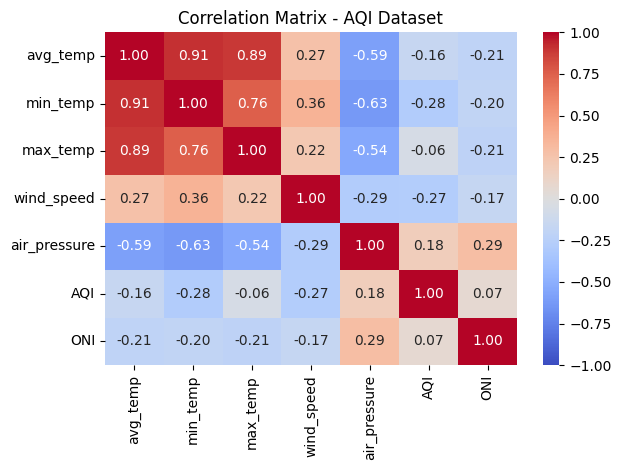

In [25]:




corr_matrix = df_clean.select_dtypes(include="number").corr()



sns.heatmap(corr_matrix,
           annot=True,       
           fmt=".2f",        
           cmap="coolwarm",  
           vmin=-1, vmax=1)  


plt.title("Correlation Matrix - AQI Dataset")
plt.tight_layout()
plt.savefig("../outputs/correlation_heatmap.png",bbox_inches="tight")
plt.show()


Task 9 a - Imputation 

In [26]:
#Highes absolute skewness AQI and min_temp 
# Using original dataset before imputation
print(f"AQI mean: {df ["AQI"].mean().round(2)}")
print(f"AQI Median: {df["AQI"].median()}")

print(f"Min Temp Mean: {df["min_temp"].mean().round(2).round(2)}")
print(f"Min Temp Median: {df["min_temp"].median().round(2)}")
df_imputation=df.copy()
print(f"Null values in Min_temp beofre imputing: {df_imputation["min_temp"].isnull().sum()}")
print(f"Null values in AQI before imputing: {df_imputation["AQI"].isnull().sum()}")
print("Choosen Strategy: Median")

min_temp_median_imp=df_imputation["min_temp"].median()
df_imputation["min_temp"]=df_imputation["min_temp"].fillna(min_temp_median_imp)
aqi_median_imp=df_imputation["AQI"].median()
df_imputation["AQI"]=df_imputation["AQI"].fillna(aqi_median_imp)
print(f"Null values in Min_temp after imputing: {df_imputation["min_temp"].isnull().sum()}")
print(f"Null values in AQI before imputing: {df_imputation["AQI"].isnull().sum()}")


# df_clean=df_clean.drop(columns=["rainfall"])


AQI mean: 155.24
AQI Median: 105.0
Min Temp Mean: 21.01
Min Temp Median: 22.73
Null values in Min_temp beofre imputing: 393
Null values in AQI before imputing: 557
Choosen Strategy: Median
Null values in Min_temp after imputing: 0
Null values in AQI before imputing: 0


Task 9 b- Spearman Correlation Heatmap

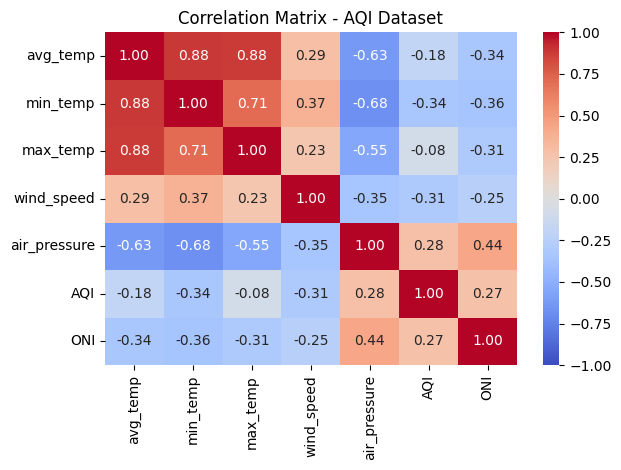

Pearson Correlation Matrix:
              avg_temp  min_temp  max_temp  wind_speed  air_pressure    AQI  \
avg_temp         1.000     0.909     0.886       0.272        -0.587 -0.161   
min_temp         0.909     1.000     0.756       0.361        -0.628 -0.283   
max_temp         0.886     0.756     1.000       0.219        -0.540 -0.060   
wind_speed       0.272     0.361     0.219       1.000        -0.287 -0.274   
air_pressure    -0.587    -0.628    -0.540      -0.287         1.000  0.179   
AQI             -0.161    -0.283    -0.060      -0.274         0.179  1.000   
ONI             -0.208    -0.195    -0.212      -0.170         0.290  0.069   

                ONI  
avg_temp     -0.208  
min_temp     -0.195  
max_temp     -0.212  
wind_speed   -0.170  
air_pressure  0.290  
AQI           0.069  
ONI           1.000  

Spearman Correlation Matrix:
              avg_temp  min_temp  max_temp  wind_speed  air_pressure    AQI  \
avg_temp         1.000     0.884     0.880       0.288

In [31]:
corr_matrix_pearson = df_clean.select_dtypes(include="number").corr()
corr_matrix_spearman = df_clean.select_dtypes(include="number").corr(method="spearman")



sns.heatmap(corr_matrix_spearman, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Matrix - AQI Dataset")
plt.tight_layout()
plt.savefig("../outputs/correlation_heatmap_spearman.png", bbox_inches="tight")
plt.show()
print("Pearson Correlation Matrix:")
print(corr_matrix_pearson.round(3))


print("\nSpearman Correlation Matrix:")
print(corr_matrix_spearman.round(3))

difference = (corr_matrix_spearman - corr_matrix_pearson).abs().round(4)
print("\nDifference Table (|Spearman - Pearson|):")
print(difference)
diff_unstacked = difference.where(~np.eye(difference.shape[0], dtype=bool)).unstack()
top3 = diff_unstacked.sort_values(ascending=False).drop_duplicates().head(3)
print("Top 3 pairs by |Spearman - Pearson| difference:")
print(top3)



Task 9c - Group aggregation 

In [28]:
df_clean.groupby("season",observed=True)["AQI"].agg(['mean','std','count']).round(2)




,mean,std,count
season,,,
Monsoon,108.31,111.91,2600
Post-monsoon,197.59,189.88,1827
Summer,120.06,103.27,3973
Winter,194.05,173.72,4752


In [29]:
print("Highest group mean to lowest group mean")
ratio=round(df_clean.groupby("season",observed=True)["AQI"].mean().round(2).max()/df_clean.groupby("season",observed=True)["AQI"].mean().round(2).min(),2)
print(ratio)

Highest group mean to lowest group mean
1.82


Task 10 - Save cleaned CSV

In [30]:
df_clean.to_csv('../Data/cleaned_data.csv',index=False)
print("Cleaned Data is stored as csv in the respctive folder ")

Cleaned Data is stored as csv in the respctive folder 
